# Notebook Prediksi PM2.5 Jakarta
Tujuan: memahami data, membersihkan, dan menemukan pola untuk feature selection

## Setup

In [1]:
%pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Import Library
import os
import warnings
from datetime import datetime

# Data Related
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from darts.dataprocessing.transformers import Scaler
from scipy.stats import ks_2samp
from sklearn.model_selection import TimeSeriesSplit

# Model Builders
import joblib
import lightgbm as lgb
import optuna
import torch
from darts import TimeSeries
from darts.models import BlockRNNModel, TFTModel

# Evaluation
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# Versioning
import mlflow
import wandb

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [ ]:
DATA_PATH = "../data/dataset/air_quality_historical.csv"
CLEAN_PATH = "../data/dataset/air_quality_clean.csv"
MODEL_PATH = "../models/model.joblib"

POLUTAN = ["pm10", "pm2_5", "carbon_monoxide", "nitrogen_dioxide", "sulphur_dioxide",
           "ozone", "aerosol_optical_depth", "dust", "uv_index"]
AQI = ["us_aqi", "european_aqi"]

BAD_DATES = ["2022-12-14", "2022-12-15"]
EXOG = ["pm10", "carbon_monoxide", "nitrogen_dioxide", "ozone", "aerosol_optical_depth"]
LAGS = [1, 2, 3, 4, 5, 7, 9, 14, 30]

TEST_DAYS, SEED, N_TRIALS, N_EPOCHS = 180, 42, 100, 30
MIN_IMPROVEMENT = 0.05
os  .makedirs("models", exist_ok=True)

EXP_ID = f"{datetime.now():%m%d-%H%M}_lags{'-'.join(map(str, LAGS))}"
print("Eksperimen:", EXP_ID)

Eksperimen: 1118-1519_lags2-9


In [4]:
%pip install python-dotenv

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
from dotenv import load_dotenv

load_dotenv() # baca WANDB_API_KEY dari file .env
if not os.getenv("WANDB_API_KEY"): # tanpa key: tetap jalan, tidak menunggu input
    os.environ["WANDB_MODE"] = "offline"
    print("W&B offline (upload nanti: wandb sync wandb/offline-run-*)")

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("pm25-jakarta")


def log_run(name: str, params: dict, metrics: dict) -> None:
    run_name = f"{EXP_ID} | {name}"
    with mlflow.start_run(run_name=run_name):
        mlflow.set_tag("exp_id", EXP_ID)
        mlflow.log_params(params)
        mlflow.log_metrics(metrics)
    with wandb.init(project="pm25-jakarta", name=run_name, group=EXP_ID,
                    config=params, reinit="finish_previous") as run:
        run.log(metrics)

## Load Data & EDA

In [6]:
raw = pd.read_csv(DATA_PATH, parse_dates=["date"])
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1298 entries, 0 to 1297
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   date                   1298 non-null   datetime64[ns]
 1   pm10                   1295 non-null   float64       
 2   pm2_5                  1295 non-null   float64       
 3   carbon_monoxide        1295 non-null   float64       
 4   nitrogen_dioxide       1295 non-null   float64       
 5   sulphur_dioxide        1295 non-null   float64       
 6   ozone                  1295 non-null   float64       
 7   aerosol_optical_depth  1295 non-null   float64       
 8   dust                   1295 non-null   float64       
 9   uv_index               1295 non-null   float64       
 10  us_aqi                 1294 non-null   float64       
 11  european_aqi           1294 non-null   float64       
dtypes: datetime64[ns](1), float64(11)
memory usage: 121.8 KB


In [7]:
raw[raw.drop(columns="date").isna().any(axis=1)]

,date,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi,european_aqi
0,2022-08-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2022-08-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-08-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2022-08-04,120.764706,83.923529,2635.176471,82.235294,23.894118,186.235294,1.228824,0.0,1.473529,NaN,NaN


In [8]:
raw.nsmallest(10, "pm2_5")[["date", "pm2_5", "pm10", "carbon_monoxide", "us_aqi"]]

,date,pm2_5,pm10,carbon_monoxide,us_aqi
136,2022-12-15,0.641667,0.920833,60.708333,13.750000
135,2022-12-14,0.712500,1.033333,59.333333,32.041667
150,2022-12-29,11.512500,16.795833,891.208333,45.375000
592,2024-03-15,12.408333,17.929167,596.750000,58.625000
155,2023-01-03,12.591667,18.195833,1008.458333,51.458333
177,2023-01-25,12.887500,18.654167,998.250000,47.583333
154,2023-01-02,13.175000,19.162500,1019.125000,56.416667
152,2022-12-31,13.375000,19.450000,789.708333,57.875000
153,2023-01-01,13.666667,19.933333,1071.916667,46.083333
593,2024-03-16,13.770833,19.862500,698.208333,53.458333


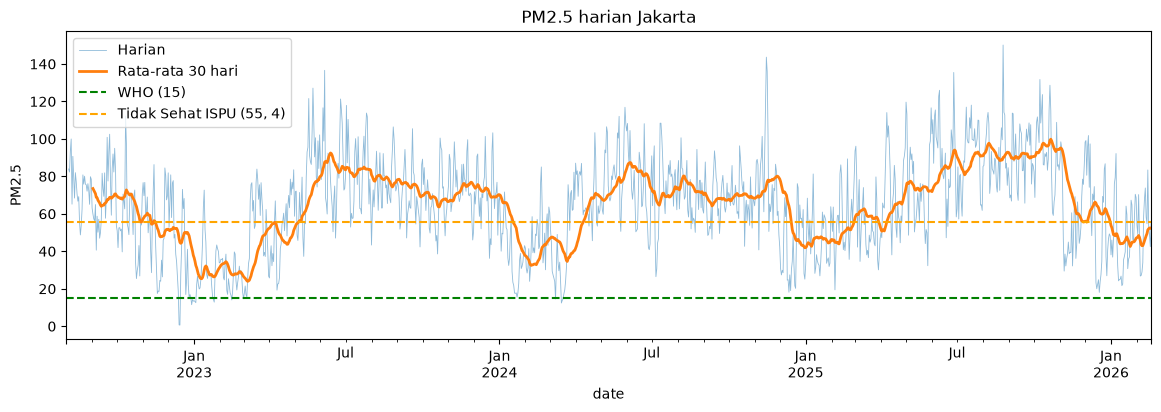

Hari di atas batas Tidak Sehat: 65.87%


In [9]:
s = raw.set_index("date")["pm2_5"]
ax = s.plot(figsize=(14,4), lw=0.6, alpha=0.5, label="Harian")
s.rolling(30).mean().plot(ax=ax, lw=2, label="Rata-rata 30 hari")
ax.axhline(15, color="green", ls="--", label="WHO (15)")
ax.axhline(55.4, color="orange", ls="--", label="Tidak Sehat ISPU (55, 4)")
ax.set(title="PM2.5 harian Jakarta", ylabel="PM2.5")
ax.legend()
plt.show()
print(f"Hari di atas batas Tidak Sehat: {(s > 55.4).mean():.2%}")

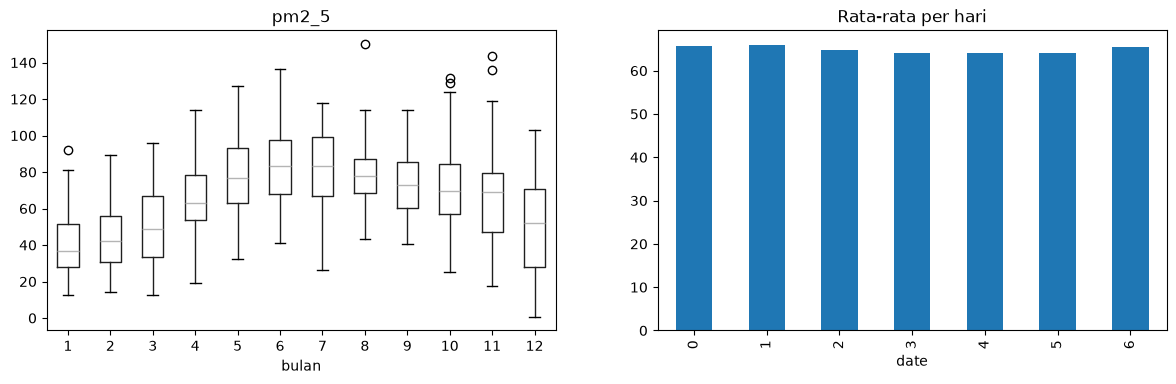

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
raw.assign(bulan=raw["date"].dt.month).boxplot(column="pm2_5", by="bulan", ax=axes[0], grid=False)
raw.groupby(raw["date"].dt.dayofweek)["pm2_5"].mean().plot.bar(ax=axes[1], title="Rata-rata per hari")
fig.suptitle("")
plt.show()

### **Temuan:** 
Musim tertinggi/terendah **Juni / Januari**, pola mingguan **65.87%** hari Tidak Sehat.
14-15 Des 2022 semua polutan dan AQI anjlok ~10x bersamaan berasal dari error sumber data.
Diganti NaN lalu diinterpolasi, tidak di-drop karena posisinya di tengah urutan waktu.

## Pre-Processing

In [11]:
def clean(raw_df = pd.DataFrame) -> pd.DataFrame:
    data = raw_df.sort_values("date").drop_duplicates("date").dropna(subset=POLUTAN)
    data.loc[data["date"].isin(pd.to_datetime(BAD_DATES)), POLUTAN + AQI] = np.nan
    data = data.set_index("date").asfreq("D")
    data[POLUTAN + AQI] = data[POLUTAN + AQI].interpolate(limit=3, limit_area="inside")
    return data.reset_index()

In [12]:
def validate(data: pd.DataFrame) -> None:
    assert data["date"].is_unique, "ada tanggal double"
    assert (data["date"].diff().dropna() == pd.Timedelta(days=1)).all(), "ada tanggal bolong"
    assert data[POLUTAN].notna().all().all(), "polutan masih ada yang kosong"
    assert data["pm2_5"].between(5, 500).all(), "PM2.5 diluar rentang wajar (5-500)"
    rho = data["pm2_5"].corr(data["us_aqi"], method="spearman")
    assert rho > 0.7, f"PM2.5 dan US AQI tidak searah (Speaerman {rho:.2f})"
    print(f"Validasi lulus: {len(data)} baris, {data['date'].min().date()} s.d. "
          f"{data['date'].max().date()} | Spearman PM2.5 vs US AQI = {rho:.2f}")

In [13]:
df = clean(raw)
validate(df)

Validasi lulus: 1295 baris, 2022-08-04 s.d. 2026-02-18 | Spearman PM2.5 vs US AQI = 0.92


In [14]:
df.to_csv(CLEAN_PATH, index=False)

## Feature Selection

In [15]:
display(df[POLUTAN + AQI].corr().style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1).format("{:.2f}"))
s_besok = df.set_index("date")["pm2_5"].shift(-1)
df.set_index("date")[POLUTAN].drop(columns="pm2_5").corrwith(s_besok).sort_values(ascending=False).round(2)

,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,aerosol_optical_depth,dust,uv_index,us_aqi,european_aqi
pm10,1.00,0.89,0.45,0.63,0.36,0.84,0.88,0.05,-0.20,0.86,0.84
pm2_5,0.89,1.00,0.51,0.64,0.56,0.69,0.77,0.08,-0.20,0.88,0.94
carbon_monoxide,0.45,0.51,1.00,0.71,0.09,0.26,0.31,0.08,-0.23,0.45,0.47
nitrogen_dioxide,0.63,0.64,0.71,1.00,-0.03,0.47,0.47,0.05,-0.30,0.60,0.60
sulphur_dioxide,0.36,0.56,0.09,-0.03,1.00,0.22,0.36,0.03,-0.13,0.50,0.54
ozone,0.84,0.69,0.26,0.47,0.22,1.00,0.82,0.02,0.02,0.78,0.66
aerosol_optical_depth,0.88,0.77,0.31,0.47,0.36,0.82,1.00,0.02,-0.34,0.77,0.73
dust,0.05,0.08,0.08,0.05,0.03,0.02,0.02,1.00,0.03,0.06,0.08
uv_index,-0.20,-0.20,-0.23,-0.30,-0.13,0.02,-0.34,0.03,1.00,-0.14,-0.18
us_aqi,0.86,0.88,0.45,0.60,0.50,0.78,0.77,0.06,-0.14,1.00,0.93


pm10                     0.72
aerosol_optical_depth    0.62
ozone                    0.61
nitrogen_dioxide         0.54
sulphur_dioxide          0.47
carbon_monoxide          0.45
dust                     0.06
uv_index                -0.10
dtype: float64

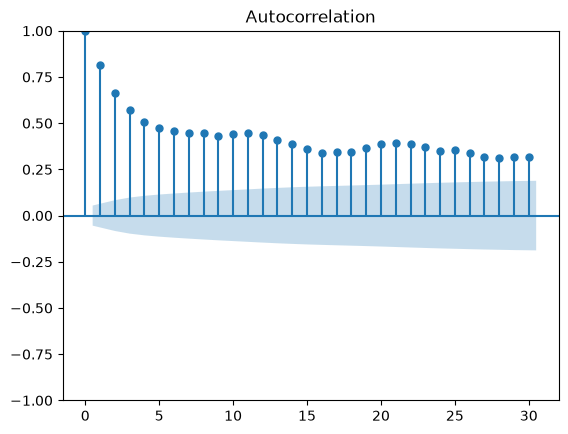

In [16]:
plot_acf(df["pm2_5"], lags=30)
plt.show()

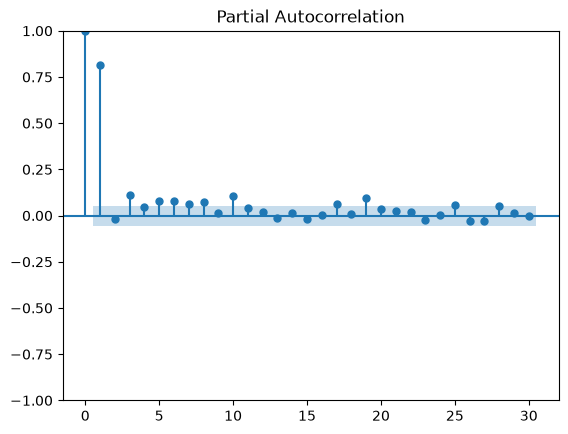

In [17]:
from statsmodels.graphics.tsaplots import plot_pacf

plot_pacf(df["pm2_5"], lags=30, method="ywm")
plt.show()

In [18]:
def build_features(data: pd.DataFrame) -> pd.DataFrame:
    d = data.set_index("date")
    x = pd.DataFrame({"pm25_today": d["pm2_5"]}) # PM2.5 hari ini (lag 1)
    for lags in LAGS:
        x[f"pm25_lag{lags}"] = d["pm2_5"].shift(lags) # PM2.5 n-hari lalu
    for w in [3, 7]:
        x[f"pm25_mean{w}"] = d["pm2_5"].rolling(w).mean() # Rata-rata 3 dan 7 hari terakhir
    x[EXOG] = d[EXOG] # Polutan lain hari ini
    x["month_sin"] = np.sin(2 * np.pi * x.index.month / 12) # Bulan dalam bentuk sin/cos
    x["month_cos"] = np.cos(2 * np.pi * x.index.month / 12) # agar Desember & Januari tidak seperti angka 12 dan 1 (rangenya jauh by value)
    x["dayofweek"] = x.index.dayofweek # Pola lalu lintas mingguan
    return x

In [19]:
def make_dataset(data: pd.DataFrame):
    full = build_features(data).join(data.set_index("date")["pm2_5"].shift(-1).rename("y")).dropna()
    split = len(full) - TEST_DAYS
    x, y = full.drop(columns="y"), full["y"]
    return x[:split], x[split:], y[:split]

In [20]:
def train_lgbm(data: pd.DataFrame, params: dict):
    x_train, x_test, y_train = make_dataset(data)
    model = lgb.LGBMRegressor(
        **params,
        subsample_freq=1,
        random_state=SEED,
        verbose=-1
    ).fit(x_train, y_train - x_train["pm25_today"])
    return model, pd.Series((model.predict(x_test) + x_test["pm25_today"].values), index=x_test.index + pd.Timedelta(days=1))

In [21]:
def evaluate(pred: pd.Series, data: pd.DataFrame) -> dict:
    d = data.set_index("date").loc[pred.index]
    return {"mae": mean_absolute_error(d["pm2_5"], pred),
            "rmse": root_mean_squared_error(d["pm2_5"], pred),
            "spearman_us_aqi": pred.corr(d["us_aqi"], method="spearman")
            }

In [22]:
x_train, x_test, y_train = make_dataset(df)
assert not set(AQI) & set(x_train.columns), "AQI tidak boleh jadi fitur"
print("Train:", x_train.shape, "| Test:", x_test.shape)

Train: (1105, 13) | Test: (180, 13)


## Model Selection & Creation

### 4.1 LightGBM + Optuna (AutoML)
Optuna mencari parameter terbaik **hanya di data train**, dinilai dengan walk-forward CV
(`TimeSeriesSplit`: latih di masa lalu, uji di masa depan). Test set tidak disentuh sampai evaluasi akhir.

In [23]:
def objective(trial: optuna.Trial) -> float:
    params = {
              "n_estimators": trial.suggest_int("n_estimators", 100, 800),
              "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
              "num_leaves": trial.suggest_int("num_leaves", 7, 63),
              "min_child_samples": trial.suggest_int("min_child_samples", 5, 50),
              "subsample": trial.suggest_float("subsample", 0.6, 1.0),
              "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0)
            }
    model = lgb.LGBMRegressor(
                    **params,
                    subsample_freq=1,
                    random_state=SEED,
                    verbose=-1
                )
    scores = []
    for tr, va in TimeSeriesSplit(n_splits=5).split(x_train):
        model.fit(x_train.iloc[tr], y_train.iloc[tr] - x_train.iloc[tr]["pm25_today"])
        pred = model.predict(x_train.iloc[va]) + x_train.iloc[va]["pm25_today"].values
        scores.append(mean_absolute_error(y_train.iloc[va], pred))
    return float(np.mean(scores))

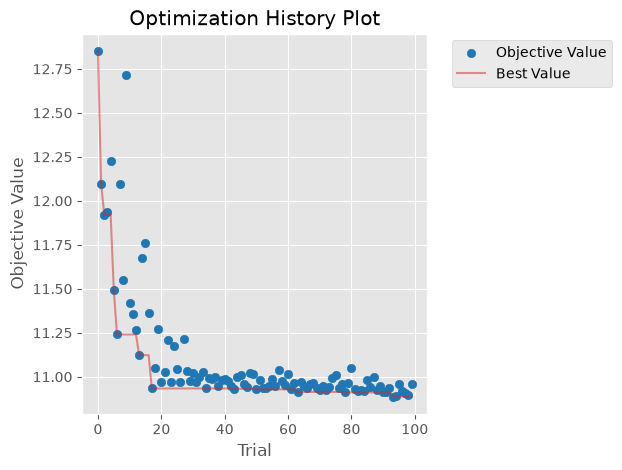

{'n_estimators': 105,
 'learning_rate': 0.011521170323864603,
 'num_leaves': 57,
 'min_child_samples': 17,
 'subsample': 0.7326187183811645,
 'colsample_bytree': 0.6986598819477455}

In [24]:
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=N_TRIALS)
LGBM_BEST = study.best_params
optuna.visualization.matplotlib.plot_optimization_history(study)
plt.show()
LGBM_BEST

In [25]:
lgbm, pred_lgbm = train_lgbm(df, LGBM_BEST)
idx = pred_lgbm.index
preds = {
    "Baseline": df.set_index("date")["pm2_5"].shift(1).loc[idx],
    "LightGBM + Optuna": pred_lgbm
    }
params = {
    "Baseline": {"model": "persistence"}, 
    "LightGBM + Optuna": {"model": "lightgbm", **LGBM_BEST}
    }
evaluate(pred_lgbm, df)

{'mae': 11.736885361894457,
 'rmse': 15.251881429658392,
 'spearman_us_aqi': np.float64(0.9304496203456802)}

### 4.2 LSTM dan TFT (Darts)
Model deep learning melihat 30 hari terakhir langsung, tanpa fitur lag buatan. Polutan lain masuk sebagai
`past_covariates`. Scaler di-fit **hanya di data train** supaya test tidak bocor. `fit_predict` menebak
"besok" untuk tiap hari test, sama seperti cara LightGBM diuji.

In [26]:
# Menyiapkan data untuk LSTM dan TFT karena 2 model ini tidak memakai fitur seperti LGBM
test_start = idx[0]
target = TimeSeries.from_dataframe(df, time_col="date", value_cols="pm2_5", freq="D").astype(np.float32)
covs = TimeSeries.from_dataframe(df, time_col="date", value_cols=EXOG, freq="D").astype(np.float32)
y_scaler = Scaler().fit(target.split_before(test_start)[0])
c_scaler = Scaler().fit(covs.split_before(test_start)[0])
target_s, covs_s = y_scaler.transform(target), c_scaler.transform(covs)
TRAINER = {
    "accelerator": "cpu", 
    "enable_progress_bar": False, 
    "enable_model_summary": False
}

In [27]:
def fit_predict(model) -> pd.Series:
    model.fit(series=target_s.split_before(test_start)[0], past_covariates=covs_s)
    pred = model.historical_forecasts(
        series=target_s,
        past_covariates=covs_s,
        start=test_start,
        forecast_horizon=1,
        retrain=False,
        verbose=False
    )
    return y_scaler.inverse_transform(pred).to_series()

4.2.1 LSTM: RNN yang membaca urutan 30 hari

In [28]:
LSTM_PARAMS = {
    "input_chunk_length": 30,
    "hidden_dim": 32,
    "dropout": 0.1,
    "n_epochs": N_EPOCHS
}

preds["LSTM"] = fit_predict(BlockRNNModel(model="LSTM", output_chunk_length=1, random_state=SEED,
                                         pl_trainer_kwargs=TRAINER, **LSTM_PARAMS))
params["LSTM"] = {"model": "lstm", **LSTM_PARAMS}
evaluate(preds["LSTM"], df)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer.fit` stopped: `max_epochs=30` reached.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


{'mae': 12.264047618442113,
 'rmse': 15.380983384124526,
 'spearman_us_aqi': np.float64(0.9161558884241724)}

4.2.2 TFT: Temporal Fusion Transformer (attention-based)

In [29]:
TFT_PARAMS = {
    "input_chunk_length": 30,
    "hidden_size": 16,
    "num_attention_heads": 2,
    "dropout": 0.1,
    "n_epochs": N_EPOCHS
}

preds["TFT"] = fit_predict(TFTModel(output_chunk_length=1, random_state=SEED, likelihood=None,
                                    loss_fn=torch.nn.MSELoss(), pl_trainer_kwargs=TRAINER,
                                    add_encoders={"cyclic": {"future": ["month"]},
                                                  "datetime_attribute": {"future": ["dayofweek"]}},
                                    **TFT_PARAMS))
params["TFT"] = {"model": "tft", **TFT_PARAMS}
evaluate(preds["TFT"], df)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer.fit` stopped: `max_epochs=30` reached.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


{'mae': 11.88316748654401,
 'rmse': 15.52611389615984,
 'spearman_us_aqi': np.float64(0.9274083570073101)}

## Eval & Tracking

In [30]:
%pip install nbformat

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [31]:
assert all(p.index.equals(idx) for p in preds.values()), "tanggal prediksi tidak sama!"
comparison = pd.DataFrame({name: evaluate(p, df) for name, p in preds.items()}).T.sort_values("mae")
for name, row in comparison.iterrows():
    log_run(name, {"test_days": TEST_DAYS, "lags": str(LAGS), **params[name]}, row.to_dict())
comparison.round(3)

wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from WANDB_API_KEY.
wandb: Currently logged in as: alvingunawansutanto (alvingunawansutanto-binus-university) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


mae,▁
rmse,▁
spearman_us_aqi,▁
mae,11.73689
rmse,15.25188
spearman_us_aqi,0.93045


mae,▁
rmse,▁
spearman_us_aqi,▁
mae,11.88317
rmse,15.52611
spearman_us_aqi,0.92741


mae,▁
rmse,▁
spearman_us_aqi,▁
mae,12.26405
rmse,15.38098
spearman_us_aqi,0.91616


mae,▁
rmse,▁
spearman_us_aqi,▁
mae,12.33174
rmse,16.5508
spearman_us_aqi,0.92397


,mae,rmse,spearman_us_aqi
LightGBM + Optuna,11.737,15.252,0.930
TFT,11.883,15.526,0.927
LSTM,12.264,15.381,0.916
Baseline,12.332,16.551,0.924
